## 1. Install and import the required libraries

In [32]:
# Install libraries (Colab usually already has most of these)
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Upload the dataset

In [33]:
# Download the CSV dataset from the Kaggle page in your assignment.
# Then click Choose Files and select the CSV file.

uploaded = files.upload()
if uploaded:
    csv_file = next(iter(uploaded))
    data = pd.read_csv(csv_file)
else:
    # Fallback to the dataset file already present in your files
    data = pd.read_csv("/content/test_genetic_disorders.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", data.shape)
data.head()

Saving test_genetic_disorders.csv to test_genetic_disorders.csv
Saving train_genetic_disorders.csv to train_genetic_disorders.csv
Dataset loaded successfully!
Rows and columns: (9463, 43)


,Patient Id,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,...,History of anomalies in previous pregnancies,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5
0,PID0x4175,6.0,No,Yes,No,No,4.981655,Charles,NaN,Kore,...,-99,2.0,Multiple,-99.000000,slightly abnormal,True,True,True,True,True
1,PID0x21f5,10.0,Yes,No,NaN,Yes,5.118890,Catherine,NaN,Homero,...,Yes,-99.0,Multiple,8.179584,normal,False,False,False,True,False
2,PID0x49b8,5.0,No,NaN,No,No,4.876204,James,NaN,Danield,...,No,0.0,Singular,-99.000000,slightly abnormal,False,False,True,True,False
3,PID0x2d97,13.0,No,Yes,Yes,No,4.687767,Brian,NaN,Orville,...,Yes,-99.0,Singular,6.884071,normal,True,False,True,False,True
4,PID0x58da,5.0,No,NaN,NaN,Yes,5.152362,Gary,NaN,Issiah,...,No,-99.0,Multiple,6.195178,normal,True,True,True,True,False


## 3. Understand the dataset

In [34]:
print("Column names:")
print(data.columns.tolist())

print("\\nDataset information:")
data.info()

print("\\nMissing values in each column:")
display(data.isnull().sum().sort_values(ascending=False))

print("\\nBasic statistics:")
display(data.describe(include="all").T)

Column names:
['Patient Id', 'Patient Age', "Genes in mother's side", 'Inherited from father', 'Maternal gene', 'Paternal gene', 'Blood cell count (mcL)', 'Patient First Name', 'Family Name', "Father's name", "Mother's age", "Father's age", 'Institute Name', 'Location of Institute', 'Status', 'Respiratory Rate (breaths/min)', 'Heart Rate (rates/min', 'Test 1', 'Test 2', 'Test 3', 'Test 4', 'Test 5', 'Parental consent', 'Follow-up', 'Gender', 'Birth asphyxia', 'Autopsy shows birth defect (if applicable)', 'Place of birth', 'Folic acid details (peri-conceptional)', 'H/O serious maternal illness', 'H/O radiation exposure (x-ray)', 'H/O substance abuse', 'Assisted conception IVF/ART', 'History of anomalies in previous pregnancies', 'No. of previous abortion', 'Birth defects', 'White Blood cell count (thousand per microliter)', 'Blood test result', 'Symptom 1', 'Symptom 2', 'Symptom 3', 'Symptom 4', 'Symptom 5']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9463 e

,0
Family Name,9316
Maternal gene,3829
Heart Rate (rates/min,3014
Respiratory Rate (breaths/min),3013
Institute Name,2170
Autopsy shows birth defect (if applicable),1345
Inherited from father,717
Genes in mother's side,173
Patient Age,173
Patient Id,173


\nBasic statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Patient Id,9290,9290,PID0x4175,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Patient Age,9290.0,NaN,NaN,NaN,7.048439,4.338143,0.0,3.0,7.0,11.0,14.0
Genes in mother's side,9290,2,Yes,5633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inherited from father,8746,2,No,5354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Maternal gene,5634,2,Yes,3181,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Paternal gene,9290,2,No,5323,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood cell count (mcL),9290.0,NaN,NaN,NaN,4.900309,0.198962,4.120469,4.766048,4.899486,5.033189,5.676184
Patient First Name,9290,1673,John,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family Name,147,140,Williams,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Father's name,9290,8175,Church,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# Show likely target columns in the loaded dataset
print("Available columns containing 'disorder' or 'sub_class' (case-insensitive):")
possible_targets = [c for c in data.columns if "disorder" in c.lower() or "class" in c.lower()]
print(possible_targets)

# Note: If this list is empty, you likely loaded the test set instead of the train set.
# The test set ('test_genetic_disorders.csv') does not contain the labels.
# Let's check if the training dataset is available in your file system:
import os
if os.path.exists("/content/train_genetic_disorders.csv") and len(possible_targets) == 0:
    print("\n[INFO] Found training set file in workspace. Automatically reloading with the training set...")
    data = pd.read_csv("/content/train_genetic_disorders.csv")
    possible_targets = [c for c in data.columns if "disorder" in c.lower() or "class" in c.lower()]

# Change this value if your dataset uses a different target-column name (e.g., 'Genetic Disorder' or 'Disorder Subclass')
TARGET_COLUMN = "Genetic Disorder" if "Genetic Disorder" in data.columns else (possible_targets[0] if possible_targets else None)

if not TARGET_COLUMN or TARGET_COLUMN not in data.columns:
    raise ValueError(
        f"Could not find a valid target column in the current dataset columns: {list(data.columns)[:10]}... "
        "Please ensure you upload and load the 'train_genetic_disorders.csv' file, not the test file."
    )

print("Target selected:", TARGET_COLUMN)
print(data[TARGET_COLUMN].value_counts(dropna=False))

Available columns containing 'disorder' or 'sub_class' (case-insensitive):
[]

[INFO] Found training set file in workspace. Automatically reloading with the training set...
Target selected: Genetic Disorder
Genetic Disorder
Mitochondrial genetic inheritance disorders     9686
Single-gene inheritance diseases                7291
NaN                                             3121
Multifactorial genetic inheritance disorders    1985
Name: count, dtype: int64


## 5. Basic data cleaning

In [36]:
# Work on a copy so the original data remains unchanged
df = data.copy()

# Remove rows where the target is missing; the model cannot learn without a label
df = df.dropna(subset=[TARGET_COLUMN])

# Remove columns that are completely empty
df = df.dropna(axis=1, how="all")

# Remove common identifier columns because IDs usually do not describe the patient
id_columns = [
    c for c in df.columns
    if c.lower().strip() in ["patient id", "patient_id", "id"]
]
df = df.drop(columns=id_columns, errors="ignore")

print("Cleaned dataset shape:", df.shape)
print("Missing target values:", df[TARGET_COLUMN].isna().sum())
display(df.head())

Cleaned dataset shape: (18962, 44)
Missing target values: 0


,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,Mother's age,...,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Genetic Disorder,Disorder Subclass
0,2.0,Yes,No,Yes,No,4.760603,Richard,NaN,Larre,NaN,...,NaN,9.857562,NaN,1.0,1.0,1.0,1.0,1.0,Mitochondrial genetic inheritance disorders,Leber's hereditary optic neuropathy
2,6.0,Yes,No,No,No,4.893297,Kimberly,NaN,Nashon,41.0,...,Singular,NaN,normal,0.0,1.0,1.0,1.0,1.0,Multifactorial genetic inheritance disorders,Diabetes
3,12.0,Yes,No,Yes,No,4.705280,Jeffery,Hoelscher,Aayaan,21.0,...,Singular,7.919321,inconclusive,0.0,0.0,1.0,0.0,0.0,Mitochondrial genetic inheritance disorders,Leigh syndrome
4,11.0,Yes,No,NaN,Yes,4.720703,Johanna,Stutzman,Suave,32.0,...,Multiple,4.098210,NaN,0.0,0.0,0.0,0.0,NaN,Multifactorial genetic inheritance disorders,Cancer
5,14.0,Yes,No,Yes,No,5.103188,Richard,NaN,Coleston,NaN,...,Multiple,10.272230,normal,1.0,0.0,0.0,1.0,0.0,Single-gene inheritance diseases,Cystic fibrosis


## 6. Exploratory Data Analysis (EDA)

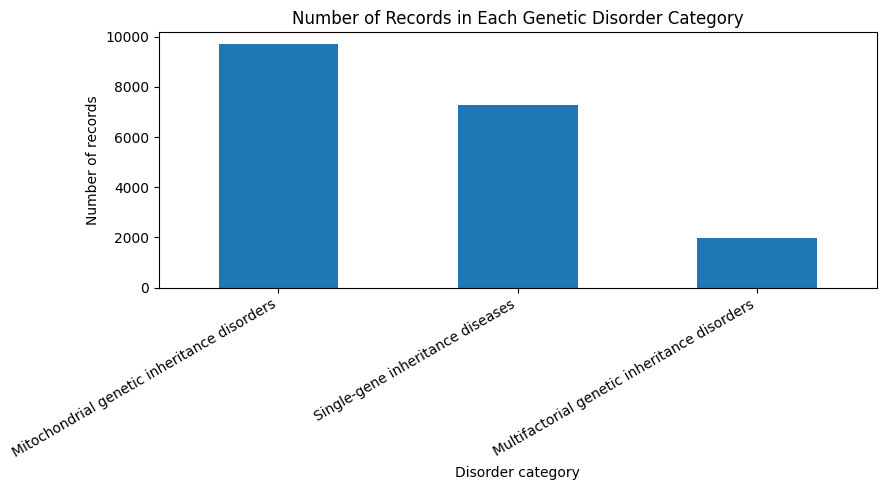

Target category percentages:


,proportion
Genetic Disorder,
Mitochondrial genetic inheritance disorders,51.08
Single-gene inheritance diseases,38.45
Multifactorial genetic inheritance disorders,10.47


In [37]:
# Count the examples in each disorder category
plt.figure(figsize=(9, 5))
df[TARGET_COLUMN].value_counts().plot(kind="bar")
plt.title("Number of Records in Each Genetic Disorder Category")
plt.xlabel("Disorder category")
plt.ylabel("Number of records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Target category percentages:")
display((df[TARGET_COLUMN].value_counts(normalize=True) * 100).round(2))

## 7. Prepare features and target

- **X** contains the input columns.
- **y** contains the answer the model should predict.
- Text categories are converted using One-Hot Encoding.
- Missing numeric values are filled with the median.
- Missing text values are filled with the most frequent value.
- Numeric columns are scaled.

The preprocessing steps are placed inside a pipeline to avoid data leakage from the test set.

In [38]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(str)

# Identify numeric and categorical columns automatically
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Numeric columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Numeric columns: 16
Categorical columns: 27


## 8. Split the dataset into training and testing data

In [39]:
# Use stratification when every class has at least 2 examples
class_counts = y.value_counts()
can_stratify = class_counts.min() >= 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y if can_stratify else None
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 15169
Testing records: 3793


## 9. Train the Logistic Regression model

In [40]:
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


## 10. Evaluate the model

In [41]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f} ({accuracy * 100:.2f}%)")

print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.963 (96.28%)
\nClassification report:
                                              precision    recall  f1-score   support

 Mitochondrial genetic inheritance disorders       0.94      0.99      0.97      1938
Multifactorial genetic inheritance disorders       0.96      0.94      0.95       397
            Single-gene inheritance diseases       1.00      0.93      0.96      1458

                                    accuracy                           0.96      3793
                                   macro avg       0.97      0.95      0.96      3793
                                weighted avg       0.96      0.96      0.96      3793



### Confusion matrix

A confusion matrix compares the actual category with the category predicted by the model. Check which categories are being confused with one another.

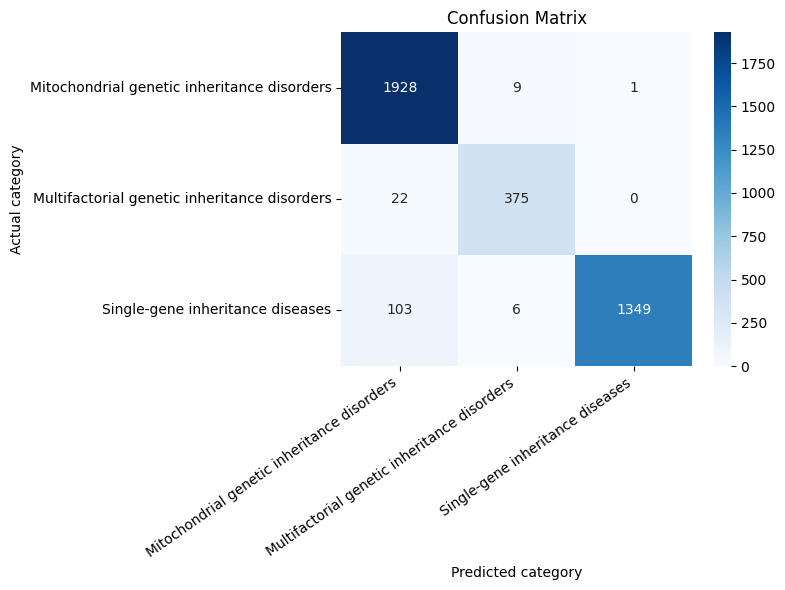

In [42]:
# Ensure y_pred is defined before generating the confusion matrix
if 'y_pred' not in globals():
    print("[INFO] 'y_pred' was not found. Generating predictions now...")
    y_pred = model.predict(X_test)

labels = model.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=labels, yticklabels=labels
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Cross-validation

Cross-validation checks model performance across multiple training/test splits. The number of folds is limited by the smallest class size.

In [43]:
minimum_class_count = int(y.value_counts().min())
n_folds = min(5, minimum_class_count)

if n_folds >= 2:
    cv_scores = cross_val_score(
        model, X, y, cv=n_folds, scoring="accuracy"
    )
    print("Cross-validation scores:", np.round(cv_scores, 3))
    print("Mean CV accuracy:", round(cv_scores.mean(), 3))
else:
    print("Cross-validation skipped: at least one class has fewer than 2 records.")

Cross-validation scores: [0.948 0.953 0.954 0.952 0.955]
Mean CV accuracy: 0.952


## 12. Make a sample prediction

In [44]:
# Predict one record from the test dataset
sample_patient = X_test.iloc[[0]]
predicted_category = model.predict(sample_patient)[0]

print("Predicted category:", predicted_category)

# Logistic Regression can provide class probabilities
if hasattr(model.named_steps["classifier"], "predict_proba"):
    probabilities = model.predict_proba(sample_patient)[0]
    print("\\nClass probabilities:")
    for category, probability in zip(labels, probabilities):
        print(f"{category}: {probability:.2%}")

display(sample_patient)

Predicted category: Single-gene inheritance diseases
\nClass probabilities:
Mitochondrial genetic inheritance disorders: 0.06%
Multifactorial genetic inheritance disorders: 0.03%
Single-gene inheritance diseases: 99.91%


,Patient Age,Genes in mother's side,Inherited from father,Maternal gene,Paternal gene,Blood cell count (mcL),Patient First Name,Family Name,Father's name,Mother's age,...,No. of previous abortion,Birth defects,White Blood cell count (thousand per microliter),Blood test result,Symptom 1,Symptom 2,Symptom 3,Symptom 4,Symptom 5,Disorder Subclass
2788,2.0,Yes,No,Yes,No,4.920906,Robert,Redmond,Vasean,31.0,...,0.0,Singular,10.28992,normal,1.0,1.0,0.0,1.0,0.0,Cystic fibrosis


## 13. Save the trained model

The saved file includes the preprocessing steps and trained classifier. You can download it and later load it in a separate application.

In [45]:
model_filename = "genetic_disorder_logistic_model.pkl"
joblib.dump(model, model_filename)

print("Model saved as:", model_filename)
files.download(model_filename)

Model saved as: genetic_disorder_logistic_model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Conclusion

Complete this short summary after running the notebook:

1. Number of records in the dataset: ______
2. Number of input features: ______
3. Target column: ______
4. Test accuracy: ______
5. Best-performing disorder category: ______
6. Category with the lowest recall: ______

### Critical-thinking question

If the model has high overall accuracy but low recall for one disorder category, accuracy alone is not enough. In a healthcare screening context, **recall for each category** deserves particular attention because low recall means some patients in that category may be missed. Precision and F1-score should also be reported, and the trade-off should be discussed with domain experts.

**Reminder:** This model is for learning and demonstration only, not for patient diagnosis or clinical decisions.